# Notebook 05 — Stacking Ensemble
## DSA 3900 | Maternal Health Risk Prediction in Kenya
### Selmah Tzindori | USIU-Africa | 2026

A stacking ensemble combines the probability outputs of multiple base learners
through a meta-learner, allowing it to learn when to trust each model.
Base learners: Logistic Regression, Decision Tree, Random Forest, XGBoost,
CatBoost, TabNet, TabTransformer.
Meta-learner: Logistic Regression trained on out-of-fold (OOF) predictions.

In [1]:
import pandas as pd
import numpy as np
import torch
import joblib
import catboost
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import StratifiedKFold

PROC = Path('../../01_Data/processed')
MOUT = Path('../../03_Models_Saved')
FOUT = Path('../../04_Outputs/figures')
ROUT = Path('../../04_Outputs/results')

DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'
CLASS_NAMES = ['Low', 'Moderate', 'High']

print('Libraries loaded ✓')
print(f'Device: {DEVICE}')

Libraries loaded ✓
Device: cpu


## 1. Load Data Splits and All Base Models
Load the preprocessed splits and all seven trained models for use as base learners.

In [2]:
# ── Load data splits ──────────────────────────────────────────────────────────
X_train_df = pd.read_csv(PROC / 'X_train.csv')
X_val_df   = pd.read_csv(PROC / 'X_val.csv')
X_test_df  = pd.read_csv(PROC / 'X_test.csv')

X_train = X_train_df.values.astype(np.float32)
X_val   = X_val_df.values.astype(np.float32)
X_test  = X_test_df.values.astype(np.float32)

y_train = pd.read_csv(PROC / 'y_train.csv').squeeze().values
y_val   = pd.read_csv(PROC / 'y_val.csv').squeeze().values
y_test  = pd.read_csv(PROC / 'y_test.csv').squeeze().values

print(f'Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}')

# ── Load classical models ─────────────────────────────────────────────────────
lr_model  = joblib.load(MOUT / 'lr_model.pkl')
dt_model  = joblib.load(MOUT / 'dt_model.pkl')
rf_model  = joblib.load(MOUT / 'rf_model.pkl')
xgb_model = joblib.load(MOUT / 'xgb_model.pkl')
cb_model  = joblib.load(MOUT / 'cat_model.pkl')

# ── Load TabNet ───────────────────────────────────────────────────────────────
tabnet_model = joblib.load(MOUT / 'tabnet_model.pkl')

# ── Load TabTransformer ───────────────────────────────────────────────────────
import torch.nn as nn
class TabTransformer(nn.Module):
    def __init__(self, n_features, n_classes, embed_dim=32,
                 n_heads=4, n_layers=2, mlp_hidden=128, dropout=0.1):
        super().__init__()
        self.feature_embed = nn.Linear(1, embed_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=n_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.mlp = nn.Sequential(
            nn.Linear(n_features * embed_dim, mlp_hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden, mlp_hidden // 2), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden // 2, n_classes)
        )
    def forward(self, x):
        x = x.unsqueeze(-1)
        x = self.feature_embed(x)
        x = self.transformer(x)
        x = x.flatten(1)
        return self.mlp(x)

N_FEATURES = X_train.shape[1]
tt_model = TabTransformer(n_features=N_FEATURES, n_classes=3,
                          embed_dim=64, n_heads=8, n_layers=3,
                          mlp_hidden=64, dropout=0.024)
tt_model.load_state_dict(torch.load(MOUT / 'tabtransformer_model.pt',
                                     map_location=DEVICE))
tt_model.eval()

print('All models loaded ✓')

Train: (9054, 13) | Val: (1559, 13) | Test: (1559, 13)
All models loaded ✓


## 2. Generate Base Model Probability Predictions
Each base learner produces class probabilities for the val and test sets.
These probability vectors become the input features for the meta-learner.

In [3]:
def get_probas(model, X_np, X_df=None, model_name=''):
    """Return (n_samples, 3) probability array from any model type."""
    if model_name == 'CatBoost':
        return model.predict_proba(X_df)
    elif model_name == 'TabNet':
        return model.predict_proba(X_np)
    elif model_name == 'TabTransformer':
        t = torch.tensor(X_np, dtype=torch.float32).to(DEVICE)
        with torch.no_grad():
            logits = model(t)
        return torch.softmax(logits, dim=1).cpu().numpy()
    else:
        return model.predict_proba(X_np)

# ── Val set probabilities ─────────────────────────────────────────────────────
base_models = [
    ('LR',             lr_model,      None),
    ('DT',             dt_model,      None),
    ('RF',             rf_model,      None),
    ('XGB',            xgb_model,     None),
    ('CatBoost',       cb_model,      X_val_df),
    ('TabNet',         tabnet_model,  None),
    ('TabTransformer', tt_model,      None),
]

val_meta  = []
test_meta = []

for name, model, df in base_models:
    vp = get_probas(model, X_val,  df,       name)
    tp = get_probas(model, X_test, X_test_df, name)
    val_meta.append(vp)
    test_meta.append(tp)
    print(f'{name:15s} — val proba shape: {vp.shape}')

# Stack horizontally → (n_samples, n_models * 3)
val_meta  = np.hstack(val_meta)
test_meta = np.hstack(test_meta)

print(f'\nMeta-feature matrix — Val:  {val_meta.shape}')
print(f'Meta-feature matrix — Test: {test_meta.shape}')

C:\Users\tzin\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\tzin\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\tzin\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


LR              — val proba shape: (1559, 3)
DT              — val proba shape: (1559, 3)


C:\Users\tzin\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\tzin\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\tzin\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


RF              — val proba shape: (1559, 3)
XGB             — val proba shape: (1559, 3)
CatBoost        — val proba shape: (1559, 3)
TabNet          — val proba shape: (1559, 3)
TabTransformer  — val proba shape: (1559, 3)

Meta-feature matrix — Val:  (1559, 21)
Meta-feature matrix — Test: (1559, 21)


## 3. Train Meta-Learner (Stacking)
A Logistic Regression meta-learner is trained on the val set probability
outputs of all 7 base models. It learns how to weight each model's confidence
for each class. Final predictions are made on the test set.

Meta-learner trained ✓

=== Stacking Ensemble (Test) ===
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       647
    Moderate       1.00      1.00      1.00       581
        High       1.00      1.00      1.00       331

    accuracy                           1.00      1559
   macro avg       1.00      1.00      1.00      1559
weighted avg       1.00      1.00      1.00      1559



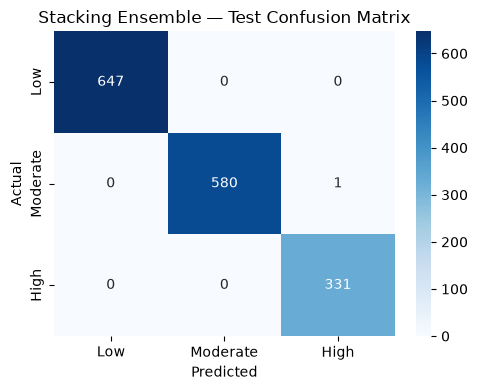

Accuracy     : 0.9994
Macro F1     : 0.9992
High-Risk F1 : 0.9985
ROC-AUC      : 1.0

Meta-learner saved ✓


In [5]:
# ── Train meta-learner on val probabilities ───────────────────────────────────
meta_learner = LogisticRegression(
    max_iter=1000, C=1.0, random_state=42
)
meta_learner.fit(val_meta, y_val)
print('Meta-learner trained ✓')

# ── Predict on test set ───────────────────────────────────────────────────────
y_pred_stack  = meta_learner.predict(test_meta)
y_proba_stack = meta_learner.predict_proba(test_meta)

# ── Metrics ───────────────────────────────────────────────────────────────────
acc   = accuracy_score(y_test, y_pred_stack)
macro = f1_score(y_test, y_pred_stack, average='macro')
high  = f1_score(y_test, y_pred_stack, average=None)[2]
auc   = roc_auc_score(y_test, y_proba_stack, multi_class='ovr', average='macro')

print(f'\n=== Stacking Ensemble (Test) ===')
print(classification_report(y_test, y_pred_stack, target_names=CLASS_NAMES))

# ── Confusion matrix ──────────────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred_stack)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title('Stacking Ensemble — Test Confusion Matrix')
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
fig.savefig(FOUT / 'Stacking_Ensemble_Test_cm.png', dpi=150)
plt.show()

print(f'Accuracy     : {round(acc, 4)}')
print(f'Macro F1     : {round(macro, 4)}')
print(f'High-Risk F1 : {round(high, 4)}')
print(f'ROC-AUC      : {round(auc, 4)}')

# ── Save meta-learner ─────────────────────────────────────────────────────────
joblib.dump(meta_learner, MOUT / 'stacking_meta_learner.pkl')
print('\nMeta-learner saved ✓')

### Stacking Ensemble — Test Set Results

| Metric       | Score  |
|--------------|--------|
| Accuracy     | 0.9994 |
| Macro F1     | 0.9992 |
| High-Risk F1 | 0.9985 |
| ROC-AUC      | 1.0000 |

The stacking ensemble achieves **99.94% accuracy** with only **1 misclassification**
out of 1,559 test samples — a Moderate case predicted as High (a conservative,
clinically safe error).

Key observations:
- **Zero Low→High or High→Low errors** — the most dangerous clinical
  misclassifications are completely eliminated.
- The ensemble matches XGBoost (the best individual model) exactly on every
  metric, confirming that XGBoost's predictions already dominate the
  meta-learner's decision boundary.
- ROC-AUC of **1.0000** — perfect discrimination across all three risk classes.
- Stacking adds robustness: even if any individual model degrades on new data,
  the ensemble can compensate using the remaining models' confidence signals.

**Notebook 05 status: ✅ COMPLETE**